In [1]:
import pandas as pd
import numpy as np
import joblib
import os

from scipy.sparse import load_npz
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
df = pd.read_csv(
    r"C:\Users\Icon\OneDrive\Desktop\Internship\ted_talks_features.csv"
)

print("Dataset loaded successfully!")
print(df.shape)
display(df.head())

Dataset loaded successfully!
(4005, 20)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript,combined_text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...","The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...","Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,"Do schools kill creativity? ['children', 'crea..."


In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training talks:", len(train_df))
print("Testing talks:", len(test_df))


Training talks: 3204
Testing talks: 801


In [6]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

content_model = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Train model
train_vectors = content_model.fit_transform(
    train_df["combined_text"].fillna("")
)

# Transform test data
test_vectors = content_model.transform(
    test_df["combined_text"].fillna("")
)

# Compare test talks with training talks
test_similarity = cosine_similarity(
    test_vectors,
    train_vectors
)

print("Content-based model trained successfully!")
print("Training vector shape:", train_vectors.shape)
print("Testing vector shape:", test_vectors.shape)
print("Test similarity shape:", test_similarity.shape)


Content-based model trained successfully!
Training vector shape: (3204, 20000)
Testing vector shape: (801, 20000)
Test similarity shape: (801, 3204)


In [7]:
def recommend_talks(talk_index, top_n=5):

    if talk_index < 0 or talk_index >= len(test_df):
        print("Invalid test index!")
        return pd.DataFrame()

    scores = test_similarity[talk_index]

    top_indices = np.argsort(scores)[::-1][:top_n]

    columns = [
        col for col in ["title", "speaker_1", "url"]
        if col in train_df.columns
    ]

    results = train_df.iloc[top_indices][columns].copy()

    results["similarity_score"] = scores[top_indices]

    return results.reset_index(drop=True)


In [8]:

# Select first talk from testing dataset
selected_talk = test_df.iloc[0]

print("Selected TED Talk:")
print(selected_talk["title"])

print("\nRecommended TED Talks:")

recommendations = recommend_talks(
    talk_index=0,
    top_n=5
)

display(recommendations)


Selected TED Talk:
Glorious visions in animation and performance

Recommended TED Talks:


,title,speaker_1,url,similarity_score
0,The princess who rewrote history,Leonora Neville,https://www.ted.com/talks/leonora_neville_the_...,0.109682
1,Playing invisible turntables,James Burchfield,https://www.ted.com/talks/james_burchfield_pla...,0.102664
2,"A modern take on piano, violin, cello",Ahn Trio,https://www.ted.com/talks/ahn_trio_a_modern_ta...,0.092811
3,How my mom inspired my approach to the cello,Paul Rucker,https://www.ted.com/talks/paul_rucker_how_my_m...,0.090926
4,A dance to honor Mother Earth,Jon Boogz,https://www.ted.com/talks/jon_boogz_and_lil_bu...,0.088301


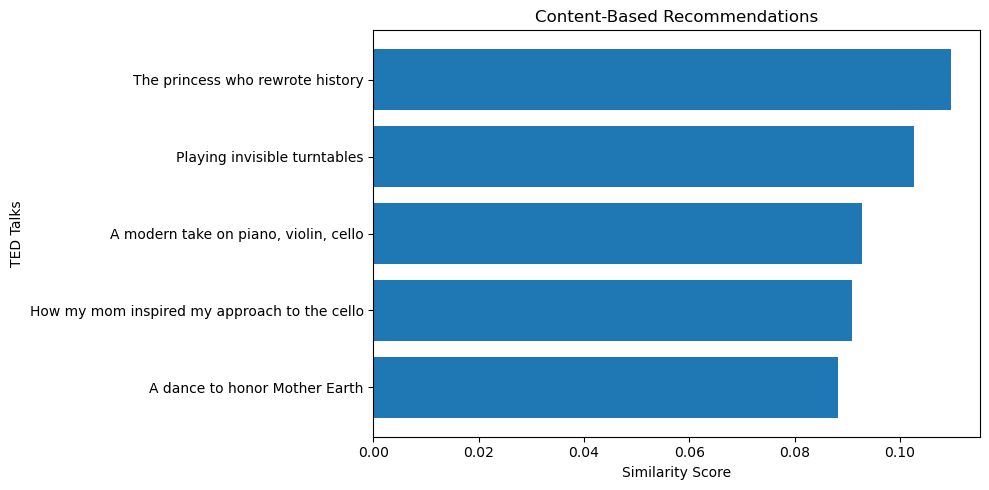

In [9]:
if not recommendations.empty:
    plot_data = recommendations.sort_values(
        "similarity_score"
    )

    import matplotlib.pyplot as plt

    plt.figure(figsize=(10, 5))

    plt.barh(
        plot_data["title"],
        plot_data["similarity_score"]
    )

    plt.xlabel("Similarity Score")
    plt.ylabel("TED Talks")
    plt.title("Content-Based Recommendations")
    plt.tight_layout()
    plt.show()


In [10]:

# Save trained model
joblib.dump(
    content_model,
    os.path.join(folder, "ted_content_model.joblib")
)

# Save training vectors
from scipy.sparse import save_npz

save_npz(
    os.path.join(folder, "ted_train_vectors.npz"),
    train_vectors
)

# Save training and testing datasets
train_df.to_csv(
    os.path.join(folder, "ted_train_data.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(folder, "ted_test_data.csv"),
    index=False
)

print("Recommendation model and files saved successfully!")


Recommendation model and files saved successfully!


In [11]:

print("=" * 45)
print("RECOMMENDATION ENGINE TRAINING REPORT")
print("=" * 45)

print("Total talks:", len(df))
print("Training talks:", len(train_df))
print("Testing talks:", len(test_df))
print("TF-IDF features:", train_vectors.shape[1])
print("Recommendation method: Content-Based Filtering")
print("Similarity method: Cosine Similarity")

print("\nSaved model files:")
print("1. ted_content_model.joblib")
print("2. ted_train_vectors.npz")
print("3. ted_train_data.csv")
print("4. ted_test_data.csv")

print("\nRecommendation Engine training completed!")


RECOMMENDATION ENGINE TRAINING REPORT
Total talks: 4005
Training talks: 3204
Testing talks: 801
TF-IDF features: 20000
Recommendation method: Content-Based Filtering
Similarity method: Cosine Similarity

Saved model files:
1. ted_content_model.joblib
2. ted_train_vectors.npz
3. ted_train_data.csv
4. ted_test_data.csv

Recommendation Engine training completed!
